## 1. Configuração do ambiente e importação das bibliotecas

As bibliotecas utilizadas nesta etapa são:
- pandas: leitura e manipulação do dataset;
- matplotlib e seaborn: criação de gráficos.
As demais bibliotecas de Machine Learning serão importadas nas etapas em que forem necessárias.

Instalação: as dependências devem ser instaladas pelo requirements.txt do projeto, e não repetidamente dentro do notebook.

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

## 2. Carregamento do dataset

O arquivo spam_ham_dataset.csv deve estar na pasta data/ do projeto. Como o notebook está na pasta notebooks/, o código considera tanto a execução a partir da raiz do projeto quanto a execução a partir da própria pasta de notebooks.

In [ ]:
# Localiza o arquivo do dataset
caminhos_dataset = [
    Path("data/spam_ham_dataset.csv"),
    Path("../data/spam_ham_dataset.csv"),
    Path("spam_ham_dataset.csv")
]

caminho_dataset = next(
    (caminho for caminho in caminhos_dataset if caminho.exists()),
    None
)

if caminho_dataset is None:
    raise FileNotFoundError(
        "Dataset não encontrado. Verifique se o arquivo "
        "ArithmeticError 'spam_ham_dataset.csv' está presente no diretório 'data' ou no diretório atual."
    )

# Carrega o dataset
df = pd.read_csv(caminho_dataset)

# Remove uma possível coluna de índice salva no arquivo CSV
df = df.loc[:, ~df.columns.str.contains(r"^Unnamed")]

print(f"Dataset carregado: {len(df)} registros")
display(df.head())

Dataset carregado: 5171 registros


,label,text,label_num
0,ham,Subject: enron methanol ; meter # : 988291\r\n...,0
1,ham,"Subject: hpl nom for january 9 , 2001\r\n( see...",0
2,ham,"Subject: neon retreat\r\nho ho ho , we ' re ar...",0
3,spam,"Subject: photoshop , windows , office . cheap ...",1
4,ham,Subject: re : indian springs\r\nthis deal is t...,0


## 3. Conhecendo a estrutura dos dados

Nesta etapa, verificamos as colunas, os tipos de dados e a quantidade de registros. Também confirmamos se as colunas necessárias para a classificação estão presentes.

In [4]:
# Informações gerais do dataset
df.info()

print("\nColunas disponíveis:")
print(df.columns.tolist())

# Verifica se as colunas necessárias existem
colunas_necessarias = {"label", "text"}
colunas_ausentes = colunas_necessarias - set(df.columns)

if colunas_ausentes:
    raise ValueError(
        f"Colunas necessárias não encontradas: {sorted(colunas_ausentes)}"
    )

<class 'pandas.DataFrame'>
RangeIndex: 5171 entries, 0 to 5170
Data columns (total 3 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   label      5171 non-null   str  
 1   text       5171 non-null   str  
 2   label_num  5171 non-null   int64
dtypes: int64(1), str(2)
memory usage: 121.3 KB

Colunas disponíveis:
['label', 'text', 'label_num']


## 4. Análise exploratória dos dados

A análise exploratória ajuda a identificar problemas que podem afetar o treinamento, como valores ausentes, mensagens duplicadas e diferenças na quantidade de exemplos de cada classe.

Valores ausentes por coluna:


label    0
text     0
dtype: int64

Mensagens duplicadas: 178
Quantidade de mensagens por classe:


label
ham     3672
spam    1499
Name: count, dtype: int64


Proporção das classes (%):


label
ham     71.01
spam    28.99
Name: count, dtype: float64

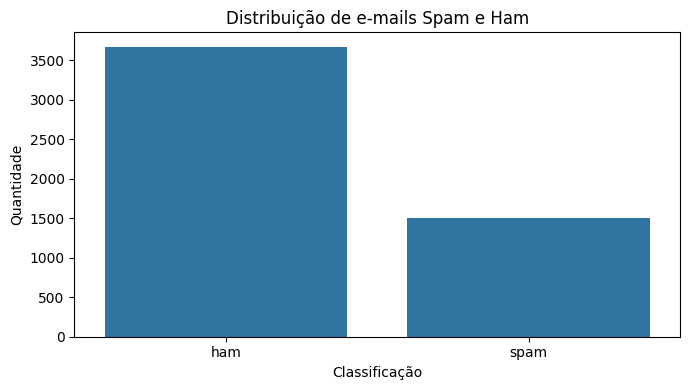

In [5]:
# Verificação de valores ausentes

valores_ausentes = df[["label", "text"]].isnull().sum()

print("Valores ausentes por coluna:")
display(valores_ausentes)

# Verificação de mensagens duplicadas

quantidade_duplicados = df.duplicated(subset=["text"]).sum()
print(f"Mensagens duplicadas: {quantidade_duplicados}")

# Distribuição das classes

distribuicao_classes = df["label"].value_counts()

print("Quantidade de mensagens por classe:")
display(distribuicao_classes)

print("\nProporção das classes (%):")
display((distribuicao_classes / len(df) * 100).round(2))

plt.figure(figsize=(7, 4))

sns.countplot(data=df, x="label", order=["ham", "spam"])

plt.title("Distribuição de e-mails Spam e Ham")
plt.xlabel("Classificação")
plt.ylabel("Quantidade")
plt.tight_layout()
plt.show()

## 5. Preparação dos dados

Nesta etapa, vamos preparar o dataset para o treinamento do SVM. Primeiro, verificaremos as mensagens duplicadas e possíveis divergências nas classificações. Em seguida, separaremos os dados de entrada e saída e criaremos os conjuntos de treinamento e teste.

### 5.1. Verificação de classificações conflitantes

In [6]:
# Identifica todas as mensagens que possuem textos repetidos
duplicados = df[
    df.duplicated(subset=["text"], keep=False)
]

# Verifica se um mesmo texto possui classificações diferentes
conflitos = duplicados.groupby("text")["label"].nunique()

quantidade_conflitos = (conflitos > 1).sum()

print("Mensagens duplicadas:", df.duplicated(subset=["text"]).sum())
print("Textos com classificações conflitantes:", quantidade_conflitos)

Mensagens duplicadas: 178
Textos com classificações conflitantes: 0


In [7]:
if quantidade_conflitos == 0:

    df_modelo = df.drop_duplicates(
        subset=["text"],
        keep="first"
    ).copy()

    print("Duplicados removidos com sucesso!")
    print("Registros antes:", len(df))
    print("Registros após:", len(df_modelo))

else:
    print("Existem classificações conflitantes.")
    print("É necessário investigar antes de remover os duplicados.")

Duplicados removidos com sucesso!
Registros antes: 5171
Registros após: 4993


### 5.2. Separação das variáveis

In [8]:
# X representa os textos que serão analisados
X = df_modelo["text"]

# y representa as classificações esperadas
y = df_modelo["label"]

print("Total de mensagens:", len(X))
print("\nDistribuição das classificações:")
print(y.value_counts())

Total de mensagens: 4993

Distribuição das classificações:
label
ham     3531
spam    1462
Name: count, dtype: int64


### 5.3. Divisão entre treinamento e teste

Os dados serão divididos em dois conjuntos: 80% para treinamento e 20% para teste. O parâmetro stratify será utilizado para preservar aproximadamente a proporção entre as classes.

In [9]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Dados de treinamento:", len(X_train))
print("Dados de teste:", len(X_test))

print("\nDistribuição no treinamento:")
print(y_train.value_counts())

print("\nDistribuição no teste:")
print(y_test.value_counts())

Dados de treinamento: 3994
Dados de teste: 999

Distribuição no treinamento:
label
ham     2825
spam    1169
Name: count, dtype: int64

Distribuição no teste:
label
ham     706
spam    293
Name: count, dtype: int64


## 6. Transformação dos textos com TF-IDF

Nesta etapa, utilizaremos o método TF-IDF para converter os textos dos e-mails em representações numéricas. Essa transformação permite que o algoritmo SVM processe os conteúdos e identifique padrões associados às classificações Spam e Ham.

In [12]:
from sklearn.feature_extraction.text import TfidfVectorizer

# Inicializa o vetorizador TF-IDF
tfidf = TfidfVectorizer()

# Aprende o vocabulário e transforma os dados de treinamento
X_train_tfidf = tfidf.fit_transform(X_train)

# Transforma os dados de teste utilizando o vocabulário aprendido
X_test_tfidf = tfidf.transform(X_test)

# Exibe algumas palavras identificadas pelo TF-IDF
palavras = tfidf.get_feature_names_out()

print("Formato dos dados de treinamento:", X_train_tfidf.shape)
print("Formato dos dados de teste:", X_test_tfidf.shape)
print("Quantidade de palavras identificadas:", len(palavras))
print("\nPrimeiras 20 palavras:")
print(palavras[:20])

Formato dos dados de treinamento: (3994, 44043)
Formato dos dados de teste: (999, 44043)
Quantidade de palavras identificadas: 44043

Primeiras 20 palavras:
['00' '000' '0000' '000000' '000000000049773' '000080' '000099' '0001'
 '00018' '00020608' '0004' '0005' '0008' '001' '0010' '0012' '001452'
 '002' '0022' '00221']


In [13]:
import pandas as pd

# Obtém os valores TF-IDF do primeiro e-mail de treinamento
valores = X_train_tfidf[0].toarray().flatten()

# Organiza as palavras e seus respectivos pesos
pesos = pd.DataFrame({
    "Palavra": palavras,
    "Peso TF-IDF": valores
})

# Exibe somente as palavras com peso maior que zero
pesos = pesos[pesos["Peso TF-IDF"] > 0]

pesos = pesos.sort_values(
    by="Peso TF-IDF",
    ascending=False
)

pesos.head(10)

,Palavra,Peso TF-IDF
40652,ua,0.402058
11247,cleburne,0.338159
13727,deal,0.303047
2280,502861,0.246796
39374,the,0.214224
29230,november,0.189192
40173,transport,0.183484
39817,to,0.173166
8606,booked,0.163061
11224,clean,0.161550


## 7. Treinamento do modelo SVM

Nesta etapa, utilizaremos o algoritmo Support Vector Machine (SVM), por meio da implementação LinearSVC da biblioteca Scikit-learn.

O modelo será treinado utilizando as representações numéricas geradas pelo TF-IDF, aprendendo padrões que permitem distinguir mensagens Spam de mensagens Ham.

### 7.1. Configuração do algoritmo

In [14]:
from sklearn.svm import LinearSVC

# Inicializa o classificador SVM
modelo_svm = LinearSVC(
    random_state=42,
    max_iter=10000
)

print("Modelo SVM configurado!")

Modelo SVM configurado!


### 7.2. Treinamento

In [15]:
# Treina o modelo utilizando os dados de treinamento
modelo_svm.fit(X_train_tfidf, y_train)

print("Treinamento do SVM concluído!")

# Realiza previsões utilizando os dados de teste
y_pred = modelo_svm.predict(X_test_tfidf)

print("Previsões realizadas!")
print("\nPrimeiras 10 previsões:")
print(y_pred[:10])

Treinamento do SVM concluído!
Previsões realizadas!

Primeiras 10 previsões:
['ham' 'ham' 'spam' 'ham' 'spam' 'spam' 'ham' 'ham' 'ham' 'spam']


## 8. Avaliação do modelo SVM

Nesta etapa, avaliaremos o desempenho do classificador utilizando métricas de classificação. Serão analisadas a acurácia, precisão, revocação e medida F1, além da matriz de confusão.

In [16]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score
)

# Calcula as métricas gerais considerando Spam como classe positiva
acuracia = accuracy_score(y_test, y_pred)

precisao = precision_score(
    y_test, y_pred,
    pos_label="spam"
)

revocacao = recall_score(
    y_test, y_pred,
    pos_label="spam"
)

f1 = f1_score(
    y_test, y_pred,
    pos_label="spam"
)

print(f"Acurácia:  {acuracia:.4f}")
print(f"Precisão:  {precisao:.4f}")
print(f"Recall:    {revocacao:.4f}")
print(f"F1-score:  {f1:.4f}")
print(
    classification_report(
        y_test,
        y_pred,
        target_names=["Ham", "Spam"],
        digits=4
    )
)

Acurácia:  0.9860
Precisão:  0.9666
Recall:    0.9863
F1-score:  0.9764
              precision    recall  f1-score   support

         Ham     0.9943    0.9858    0.9900       706
        Spam     0.9666    0.9863    0.9764       293

    accuracy                         0.9860       999
   macro avg     0.9804    0.9861    0.9832       999
weighted avg     0.9862    0.9860    0.9860       999



### 8.1. Matriz de confusão

A matriz de confusão permite identificar a quantidade de classificações corretas e incorretas realizadas pelo SVM, separando os resultados entre as classes Ham e Spam.

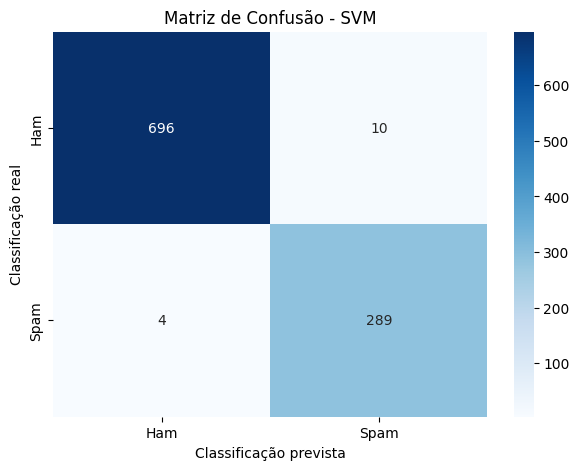

In [17]:
matriz = confusion_matrix(
    y_test,
    y_pred,
    labels=["ham", "spam"]
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    matriz,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Ham", "Spam"],
    yticklabels=["Ham", "Spam"]
)

plt.title("Matriz de Confusão - SVM")
plt.xlabel("Classificação prevista")
plt.ylabel("Classificação real")

plt.show()

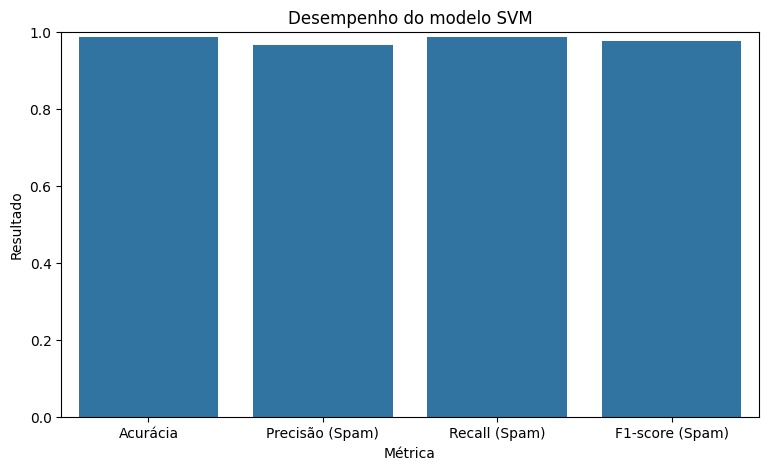

In [18]:
metricas = pd.DataFrame({
    "Métrica": [
        "Acurácia",
        "Precisão (Spam)",
        "Recall (Spam)",
        "F1-score (Spam)"
    ],
    "Resultado": [
        acuracia,
        precisao,
        revocacao,
        f1
    ]
})

plt.figure(figsize=(9, 5))

sns.barplot(
    data=metricas,
    x="Métrica",
    y="Resultado"
)

plt.title("Desempenho do modelo SVM")
plt.ylabel("Resultado")
plt.xlabel("Métrica")
plt.ylim(0, 1)

plt.show()

## 9. Testes com novos e-mails

Nesta etapa, serão realizadas previsões com mensagens que não pertencem ao conjunto de dados utilizado no treinamento e na avaliação. O objetivo é observar o comportamento do classificador diante de novos exemplos.

In [19]:
novos_emails = [
    "Congratulations! You have won a free prize. Click here now!",
    "Hello, can we schedule a meeting for tomorrow?",
    "You have been selected to receive a free gift. Claim now!",
    "Please find attached the report from our last meeting."
]

novos_emails_tfidf = tfidf.transform(novos_emails)

previsoes_novas = modelo_svm.predict(novos_emails_tfidf)

for email, classificacao in zip(novos_emails, previsoes_novas):
    print("E-mail:", email)
    print("Classificação:", classificacao.upper())
    print("-" * 70)

E-mail: Congratulations! You have won a free prize. Click here now!
Classificação: SPAM
----------------------------------------------------------------------
E-mail: Hello, can we schedule a meeting for tomorrow?
Classificação: HAM
----------------------------------------------------------------------
E-mail: You have been selected to receive a free gift. Claim now!
Classificação: SPAM
----------------------------------------------------------------------
E-mail: Please find attached the report from our last meeting.
Classificação: HAM
----------------------------------------------------------------------


## 10. Resumo dos resultados

Nesta seção, serão apresentados os principais indicadores de desempenho obtidos pelo modelo SVM no conjunto de teste.

In [20]:
resultados_svm = pd.DataFrame([{
    "Modelo": "SVM",
    "Acurácia": acuracia,
    "Precisão (Spam)": precisao,
    "Recall (Spam)": revocacao,
    "F1-score (Spam)": f1
}])

resultados_svm

,Modelo,Acurácia,Precisão (Spam),Recall (Spam),F1-score (Spam)
0,SVM,0.985986,0.966555,0.986348,0.976351


In [21]:
import joblib

joblib.dump(
    {
        "modelo": modelo_svm,
        "tfidf": tfidf
    },
    "modelo_svm.pkl"
)

print("Modelo e vetorizador salvos com sucesso!")

Modelo e vetorizador salvos com sucesso!
